In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster


In [2]:
POLLUTANTS = ["pm25", "pm10"]
LAGGED_DAYS = (1, 2, 3)
ROLLING_WINDOWS = (3, 7)
MAX_CLUSTERS = 8

WINTER_SHARE_THRESHOLD = 0.6
DBSCAN_MIN_SAMPLES_CANDIDATES = [5, 8, 10, 15, 20]

SEASONS = ["winter", "spring", "summer", "autumn"]
SEASON_MAP = {
    12: "winter", 1: "winter", 2: "winter",
    3: "spring", 4: "spring", 5: "spring",
    6: "summer", 7: "summer", 8: "summer",
    9: "autumn", 10: "autumn", 11: "autumn",
}


In [3]:
PROCESSED_DIR = Path("../data/processed")


In [4]:
def build_cluster_matrix(df, pollutant):
    weather_cols = [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "precipitation_sum",
        "pressure_msl_mean",
    ]

    base_cols = [pollutant] + weather_cols + ["rain_indicator"]
    required = base_cols + ["date", "station_id"]

    day_df = (
        df.dropna(subset=required)
        .groupby("date", as_index=False)
        .agg(**{c: pd.NamedAgg(c, "mean") for c in base_cols},
             wind_category=("wind_category", "first"),
             n_stations=("station_id", "nunique"))
    )

    wind_dummies = pd.get_dummies(day_df["wind_category"], prefix="wind")
    X_cont = RobustScaler().fit_transform(day_df[base_cols])
    X = pd.concat([
        pd.DataFrame(X_cont, columns=base_cols).reset_index(drop=True),
        wind_dummies.reset_index(drop=True),
    ], axis=1)

    return day_df, X


In [5]:
runs = {}

for pollutant in POLLUTANTS:
    df = pd.read_parquet(PROCESSED_DIR / f"features_{pollutant}.parquet")
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    cluster_df, X = build_cluster_matrix(df, pollutant)

    pca = PCA(n_components=0.90, random_state=42)
    X_pca = pca.fit_transform(X)

    print(f"{pollutant.upper()}: {len(cluster_df):,} days (one row per day) | input features: {X.shape[1]} | "
          f"PCA components: {X_pca.shape[1]} ({pca.explained_variance_ratio_.sum():.1%} variance kept)")

    runs[pollutant] = {"cluster_df": cluster_df, "X": X, "X_pca": X_pca}


PM25: 1,711 days (one row per day) | input features: 10 | PCA components: 1 (92.0% variance kept)
PM10: 2,119 days (one row per day) | input features: 10 | PCA components: 2 (93.7% variance kept)


In [6]:
def scan_k_values(X_pca, pollutant):
    ks = range(2, MAX_CLUSTERS + 1)
    inertias = []
    silhouettes = []

    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_pca, km.labels_))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(list(ks), inertias, marker="o")
    axes[0].set_xlabel("Number of clusters")
    axes[0].set_ylabel("Inertia (within-cluster SSE)")
    axes[0].set_title(f"Elbow method - {pollutant.upper()}")

    axes[1].plot(list(ks), silhouettes, marker="o")
    axes[1].set_xlabel("Number of clusters")
    axes[1].set_ylabel("Silhouette score")
    axes[1].set_title(f"Silhouette score - {pollutant.upper()}")

    plt.tight_layout()
    plt.show()

    return {"ks": list(ks), "inertias": inertias, "silhouettes": silhouettes}



PM25


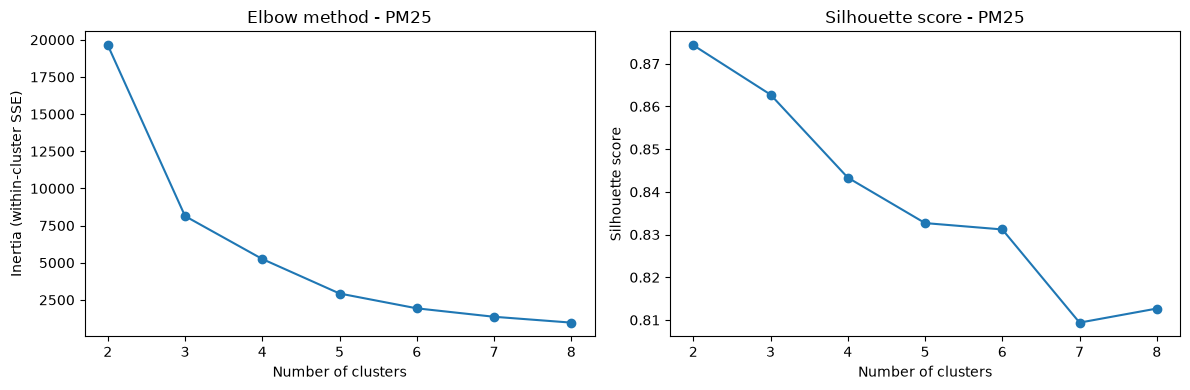


PM10


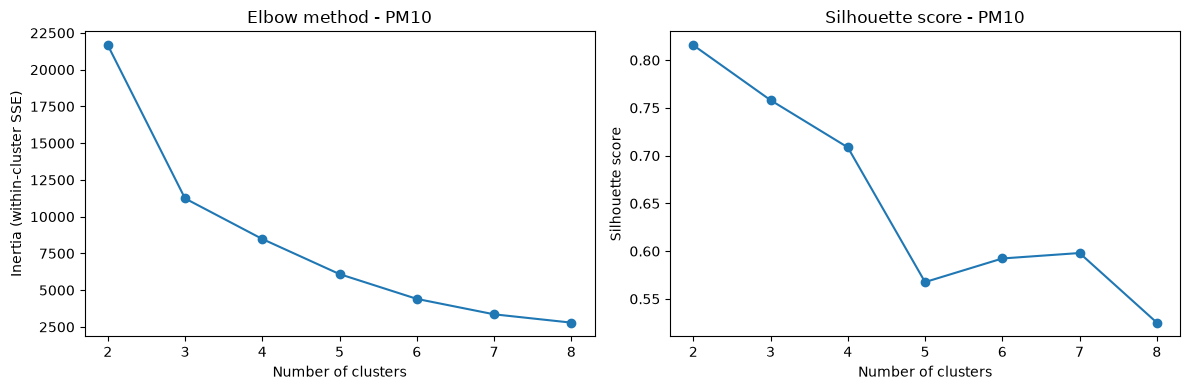

In [7]:
for pollutant in POLLUTANTS:
    print(f"\n{pollutant.upper()}")
    runs[pollutant].update(scan_k_values(runs[pollutant]["X_pca"], pollutant))


In [8]:
def scan_regimes(cluster_df, X_pca, pollutant, ks):
    regime_scan = []

    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
        labels = km.labels_
        tmp = cluster_df.assign(c=labels)
        pm_by_cluster = tmp.groupby("c")[pollutant].mean()
        top_idx = pm_by_cluster.idxmax()
        top_mask = tmp["c"] == top_idx
        winter_share = tmp.loc[top_mask, "date"].dt.month.map(SEASON_MAP).eq("winter").mean()
        regime_scan.append({
            "k": k,
            "silhouette": silhouette_score(X_pca, labels),
            "top_cluster_size": int(top_mask.sum()),
            "top_pm_mean": round(float(pm_by_cluster.loc[top_idx]), 1),
            "top_winter_share": round(float(winter_share), 2),
        })

    return pd.DataFrame(regime_scan)


In [9]:
for pollutant in POLLUTANTS:
    entry = runs[pollutant]
    scan_df = scan_regimes(entry["cluster_df"], entry["X_pca"], pollutant, entry["ks"])
    entry["scan_df"] = scan_df

    display(scan_df)

    silhouette_best_k = int(entry["ks"][int(np.argmax(entry["silhouettes"]))])
    winter_candidates = scan_df.loc[scan_df["top_winter_share"] >= WINTER_SHARE_THRESHOLD]

    print(f"\n{pollutant.upper()} — silhouette-best k: {silhouette_best_k}")
    print(f"k-selection criterion (pre-registered heuristic): smallest k whose highest-pollution cluster "
          f"has winter share >= {WINTER_SHARE_THRESHOLD}")

    if len(winter_candidates):
        best_k = int(winter_candidates["k"].min())
        winter_share = winter_candidates.loc[winter_candidates["k"] == best_k, "top_winter_share"].iloc[0]
        print(f"Chosen k: {best_k} (criterion first met at this k, top cluster winter share {winter_share:.2f})")
    else:
        best_k = silhouette_best_k
        print(f"Criterion not met for any k in 2..{MAX_CLUSTERS}; falling back to silhouette-best k={best_k}")

    entry["best_k"] = best_k


,k,silhouette,top_cluster_size,top_pm_mean,top_winter_share
0,2,0.874335,1566,25.9,0.24
1,3,0.862763,1512,25.9,0.24
2,4,0.843331,1463,26.0,0.24
3,5,0.832692,1402,26.2,0.24
4,6,0.831202,1393,26.2,0.24
5,7,0.809388,1306,26.4,0.24
6,8,0.812685,1310,26.3,0.24



PM25 — silhouette-best k: 2
k-selection criterion (pre-registered heuristic): smallest k whose highest-pollution cluster has winter share >= 0.6
Criterion not met for any k in 2..8; falling back to silhouette-best k=2


,k,silhouette,top_cluster_size,top_pm_mean,top_winter_share
0,2,0.815637,1938,51.0,0.25
1,3,0.758080,1851,51.3,0.25
2,4,0.708664,1800,51.5,0.25
3,5,0.567620,330,116.6,0.74
4,6,0.592329,321,117.6,0.75
5,7,0.598043,299,121.2,0.76
6,8,0.525158,140,157.7,0.88



PM10 — silhouette-best k: 2
k-selection criterion (pre-registered heuristic): smallest k whose highest-pollution cluster has winter share >= 0.6
Chosen k: 5 (criterion first met at this k, top cluster winter share 0.74)


In [10]:
def tune_dbscan(X_pca, pollutant):
    fig, ax = plt.subplots(figsize=(7, 4))
    for ms in DBSCAN_MIN_SAMPLES_CANDIDATES:
        nn = NearestNeighbors(n_neighbors=ms).fit(X_pca)
        dist, _ = nn.kneighbors(X_pca)
        ax.plot(np.sort(dist[:, -1]), label=f"min_samples={ms}")
    ax.set_xlabel("point index (sorted by k-th neighbour distance)")
    ax.set_ylabel("k-th nearest neighbour distance")
    ax.set_title(f"DBSCAN: k-distance curves - {pollutant.upper()}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    grid_results = []
    for ms in DBSCAN_MIN_SAMPLES_CANDIDATES:
        for eps in np.arange(0.3, 1.51, 0.05):
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_pca)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            noise_frac = (labels == -1).mean()
            if noise_frac > 0.15 or not (2 <= n_clusters <= 6):
                continue
            sil = silhouette_score(X_pca[labels != -1], labels[labels != -1])
            score = sil - 0.30 * noise_frac
            grid_results.append({"eps": eps, "min_samples": ms, "silhouette": sil,
                                 "n_clusters": n_clusters, "noise_frac": noise_frac,
                                 "score": score})

    best_dbscan = max(grid_results, key=lambda r: r["score"])
    print(f"DBSCAN grid search: eps={best_dbscan['eps']:.2f}, min_samples={best_dbscan['min_samples']} "
          f"-> {best_dbscan['n_clusters']} clusters, {best_dbscan['noise_frac']:.1%} noise, "
          f"silhouette={best_dbscan['silhouette']:.3f}")

    return best_dbscan



PM25


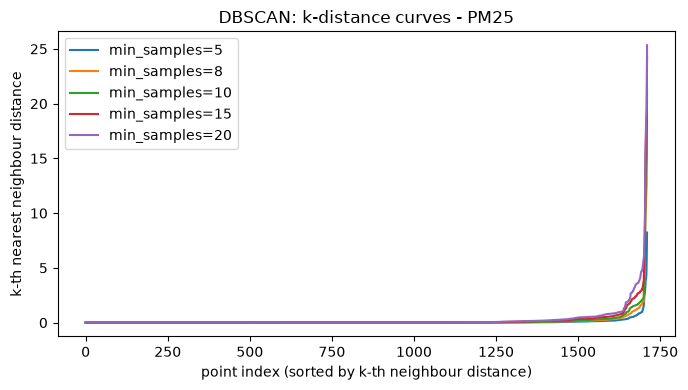

DBSCAN grid search: eps=1.10, min_samples=5 -> 2 clusters, 0.6% noise, silhouette=0.860

PM10


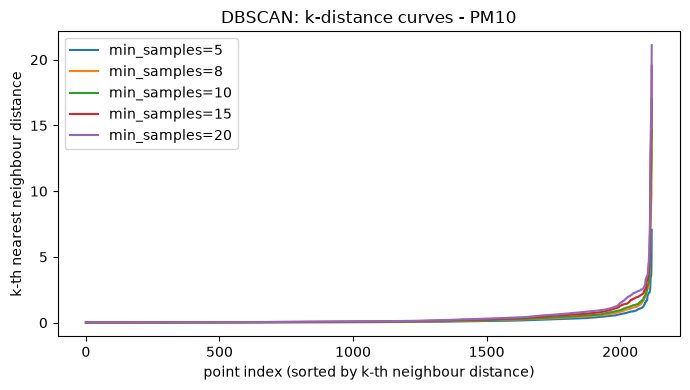

DBSCAN grid search: eps=1.50, min_samples=15 -> 2 clusters, 2.0% noise, silhouette=0.836


In [11]:
for pollutant in POLLUTANTS:
    print(f"\n{pollutant.upper()}")
    runs[pollutant]["dbscan"] = tune_dbscan(runs[pollutant]["X_pca"], pollutant)


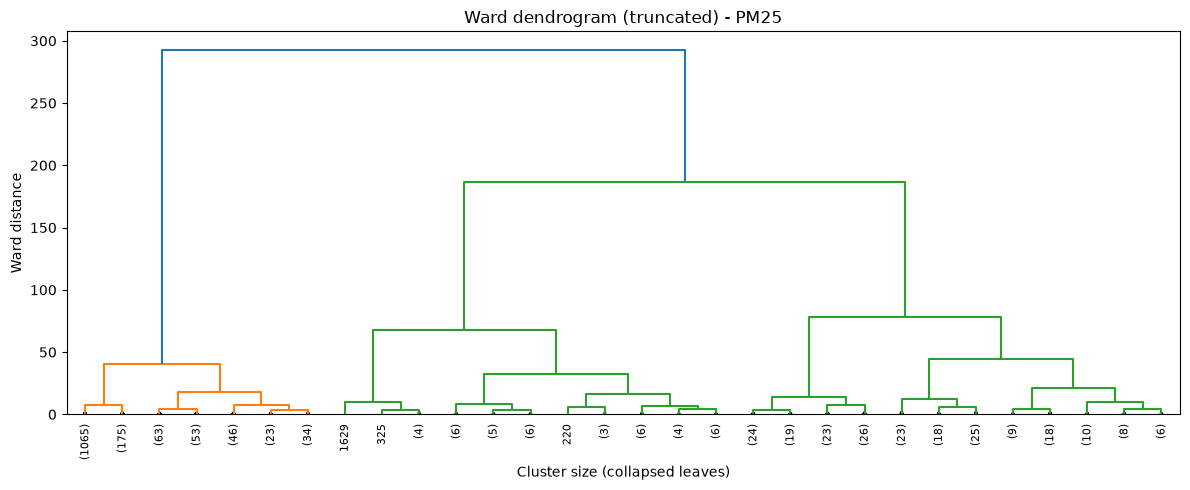

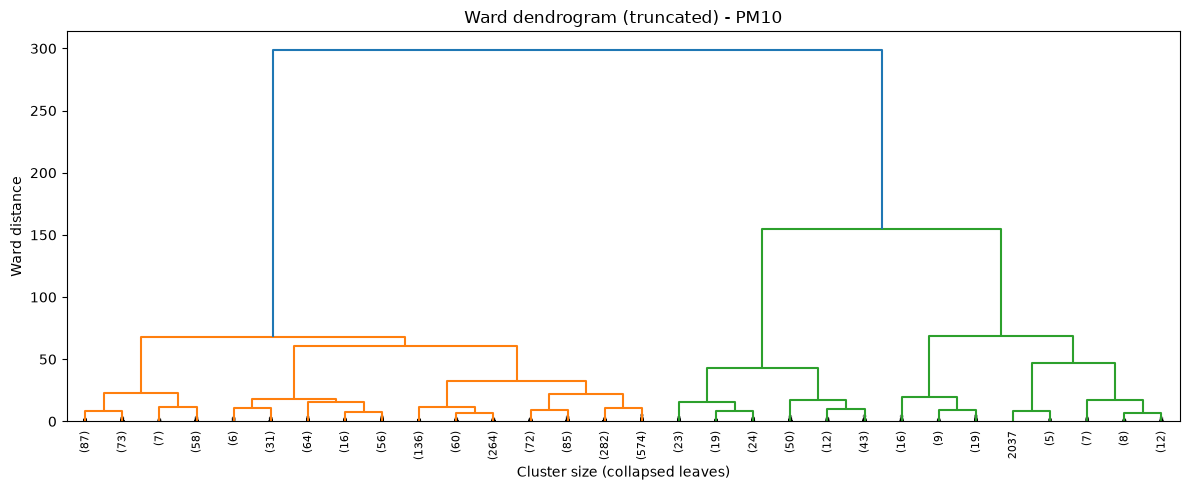

In [12]:
for pollutant in POLLUTANTS:
    entry = runs[pollutant]
    entry["hc_linkage"] = linkage(entry["X_pca"], method="ward")

    plt.figure(figsize=(12, 5))
    dendrogram(entry["hc_linkage"], truncate_mode="lastp", p=30, show_contracted=True,
               leaf_rotation=90.0, leaf_font_size=8.0)
    plt.title(f"Ward dendrogram (truncated) - {pollutant.upper()}")
    plt.xlabel("Cluster size (collapsed leaves)")
    plt.ylabel("Ward distance")
    plt.tight_layout()
    plt.show()


In [13]:
for pollutant in POLLUTANTS:
    entry = runs[pollutant]
    best_k = entry["best_k"]

    kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    gmm = GaussianMixture(n_components=best_k, random_state=42)
    dbscan = DBSCAN(eps=entry["dbscan"]["eps"], min_samples=entry["dbscan"]["min_samples"])

    kmeans_labels = kmeans.fit_predict(entry["X_pca"])
    gmm_labels = gmm.fit_predict(entry["X_pca"])
    dbscan_labels = dbscan.fit_predict(entry["X_pca"])
    hierarchical_labels = fcluster(entry["hc_linkage"], t=best_k, criterion="maxclust")

    entry["cluster_df"]["cluster_kmeans"] = kmeans_labels
    entry["cluster_df"]["cluster_gmm"] = gmm_labels
    entry["cluster_df"]["cluster_dbscan"] = dbscan_labels
    entry["cluster_df"]["cluster_hierarchical"] = hierarchical_labels

    non_noise = dbscan_labels != -1

    print(f"\n{pollutant.upper()} (k={best_k}, {len(entry['cluster_df']):,} days)")
    print(f"Silhouette on all days          : K-Means {silhouette_score(entry['X_pca'], kmeans_labels):.3f} | "
          f"GMM {silhouette_score(entry['X_pca'], gmm_labels):.3f} | "
          f"Hierarchical {silhouette_score(entry['X_pca'], hierarchical_labels):.3f}")
    print(f"Silhouette on DBSCAN-clustered days only (common support, {non_noise.sum()} days): "
          f"K-Means {silhouette_score(entry['X_pca'][non_noise], kmeans_labels[non_noise]):.3f} | "
          f"GMM {silhouette_score(entry['X_pca'][non_noise], gmm_labels[non_noise]):.3f} | "
          f"Hierarchical {silhouette_score(entry['X_pca'][non_noise], hierarchical_labels[non_noise]):.3f} | "
          f"DBSCAN {silhouette_score(entry['X_pca'][non_noise], dbscan_labels[non_noise]):.3f}")

    rng = np.random.default_rng(42)
    aris = []
    for _ in range(20):
        idx = rng.choice(len(entry["X_pca"]), size=int(0.8 * len(entry["X_pca"])), replace=True)
        boot_km = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit(entry["X_pca"][idx])
        aris.append(adjusted_rand_score(kmeans_labels, boot_km.predict(entry["X_pca"])))
    print(f"Bootstrap stability of K-Means k={best_k} (20 x 80% resamples, ARI vs full-data labels): "
          f"{np.mean(aris):.3f} +/- {np.std(aris):.3f}")



PM25 (k=2, 1,711 days)
Silhouette on all days          : K-Means 0.874 | GMM 0.455 | Hierarchical 0.833


Silhouette on DBSCAN-clustered days only (common support, 1701 days): K-Means 0.874 | GMM 0.469 | Hierarchical 0.843 | DBSCAN 0.860


Bootstrap stability of K-Means k=2 (20 x 80% resamples, ARI vs full-data labels): 0.951 +/- 0.065

PM10 (k=5, 2,119 days)


Silhouette on all days          : K-Means 0.568 | GMM 0.242 | Hierarchical 0.552


Silhouette on DBSCAN-clustered days only (common support, 2076 days): K-Means 0.569 | GMM 0.251 | Hierarchical 0.552 | DBSCAN 0.836


Bootstrap stability of K-Means k=5 (20 x 80% resamples, ARI vs full-data labels): 0.905 +/- 0.044


In [14]:
def describe_clusters(frame, label_col, pollutant):
    frame = frame.copy()
    frame[label_col] = frame[label_col].map(lambda v: "-1 (noise)" if v == -1 else str(v))
    frame["month"] = frame["date"].dt.month
    frame["season"] = frame["month"].map(SEASON_MAP)

    summary = (
        frame.groupby(label_col)
        .agg(n_days=("date", "size"),
             pm_mean=(pollutant, "mean"),
             temperature_mean=("temperature_2m_mean", "mean"),
             humidity_mean=("relative_humidity_2m_mean", "mean"),
             wind_mean=("wind_speed_10m_mean", "mean"),
             precipitation_mean=("precipitation_sum", "mean"),
             pressure_mean=("pressure_msl_mean", "mean"),
             mean_month=("month", "mean"))
        .reset_index()
    )

    season_counts = frame.groupby([label_col, "season"]).size().reset_index(name="n")
    season_counts["share"] = season_counts["n"] / season_counts.groupby(label_col)["n"].transform("sum")
    season_shares = (
        season_counts.pivot(index=label_col, columns="season", values="share")
        .reindex(columns=SEASONS)
        .fillna(0.0)
        .add_prefix("share_")
        .reset_index()
    )

    summary = summary.merge(season_shares, on=label_col, how="left")
    summary["mean_month"] = summary["mean_month"].round(1)
    summary["top_season"] = summary[[f"share_{s}" for s in SEASONS]].idxmax(axis=1).str.replace("share_", "")
    return summary


In [15]:
summaries = {}

for pollutant in POLLUTANTS:
    summaries[pollutant] = {}

    for label_col in ["cluster_kmeans", "cluster_gmm", "cluster_dbscan", "cluster_hierarchical"]:
        print(f"\n{pollutant.upper()} — {label_col}")
        summary = describe_clusters(runs[pollutant]["cluster_df"], label_col, pollutant)
        summaries[pollutant][label_col] = summary
        display(summary)



PM25 — cluster_kmeans


,cluster_kmeans,n_days,pm_mean,temperature_mean,humidity_mean,wind_mean,precipitation_mean,pressure_mean,mean_month,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,145,18.508416,10.987557,81.324425,1.652848,12.030345,1012.408218,7.0,0.234483,0.268966,0.137931,0.358621,autumn
1,1,1566,25.872559,14.649252,60.906343,1.461313,0.475990,1017.380404,6.8,0.236909,0.223499,0.269476,0.270115,autumn



PM25 — cluster_gmm


,cluster_gmm,n_days,pm_mean,temperature_mean,humidity_mean,wind_mean,precipitation_mean,pressure_mean,mean_month,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,653,21.933540,13.152093,70.870852,1.586734,3.812711,1014.287666,6.7,0.238897,0.251149,0.238897,0.271057,autumn
1,1,1058,27.294467,15.071463,57.554545,1.410153,0.000095,1018.607806,6.9,0.235350,0.212665,0.270321,0.281664,autumn



PM25 — cluster_dbscan


...

,cluster_gmm,n_days,pm_mean,temperature_mean,humidity_mean,wind_mean,precipitation_mean,pressure_mean,mean_month,share_winter,share_spring,share_summer,share_autumn,top_season
0,0,572,81.570391,7.060948,67.861524,1.372886,0.000524,1021.802389,7.1,0.538462,0.124126,0.019231,0.318182,winter
1,1,286,41.442221,11.928875,73.982809,1.632453,3.629021,1013.416434,6.5,0.290210,0.272727,0.174825,0.262238,winter
2,2,391,45.379729,13.754923,66.148231,1.580886,0.484655,1015.699670,6.5,0.245524,0.230179,0.271100,0.253197,summer
3,3,149,26.502938,11.545414,80.865213,1.692268,13.224832,1012.273881,7.3,0.201342,0.268456,0.154362,0.375839,autumn
4,4,721,33.663165,20.595151,49.734281,1.437542,0.000000,1016.589026,6.8,0.018031,0.288488,0.434119,0.259362,summer



PM10 — cluster_dbscan


,cluster_dbscan,n_days,pm_mean,temperature_mean,humidity_mean,wind_mean,precipitation_mean,pressure_mean,mean_month,share_winter,share_spring,share_summer,share_autumn,top_season
0,-1 (noise),43,67.507818,9.040407,84.022287,1.684535,17.165116,1013.388372,6.2,0.348837,0.279070,0.093023,0.279070,winter
1,0,2061,49.101733,13.988780,62.533883,1.484381,1.057205,1017.217520,6.8,0.247938,0.229015,0.241145,0.281902,autumn
2,1,15,24.852342,11.896944,83.458333,1.811333,18.746667,1011.675000,7.7,0.266667,0.200000,0.133333,0.400000,autumn



PM10 — cluster_hierarchical


,cluster_hierarchical,n_days,pm_mean,temperature_mean,humidity_mean,wind_mean,precipitation_mean,pressure_mean,mean_month,share_winter,share_spring,share_summer,share_autumn,top_season
0,1,225,133.803646,3.964704,71.275185,1.244802,0.065333,1023.122204,6.7,0.826667,0.004444,0.000000,0.168889,winter
1,2,1646,39.872421,15.662437,59.404010,1.502970,0.383414,1016.945006,6.8,0.168287,0.257594,0.283718,0.290401,autumn
2,3,171,38.405388,11.004703,78.822612,1.573631,7.018713,1012.897393,6.7,0.292398,0.251462,0.152047,0.304094,autumn
3,4,44,31.800261,11.401326,82.677083,1.747756,14.197727,1012.202462,8.2,0.159091,0.250000,0.136364,0.454545,autumn
4,5,33,23.391919,10.368939,85.296717,1.786477,22.045455,1012.115025,6.9,0.303030,0.242424,0.121212,0.333333,autumn


In [16]:
for pollutant in POLLUTANTS:
    cluster_df = runs[pollutant]["cluster_df"]

    LABELS_OUT = PROCESSED_DIR / f"clustering_labels_{pollutant}.parquet"
    SUMMARY_COLS = ["date", pollutant, "n_stations", "cluster_kmeans", "cluster_gmm", "cluster_dbscan", "cluster_hierarchical"]

    cluster_df[SUMMARY_COLS].to_parquet(LABELS_OUT, index=False)

    summary_list = []
    for label_col, summary in summaries[pollutant].items():
        summary_list.append(summary.assign(method=label_col))

    summary_df = pd.concat(summary_list, ignore_index=True)
    summary_df.to_parquet(PROCESSED_DIR / f"clustering_summary_{pollutant}.parquet", index=False)

    print(f"Saved: clustering_labels_{pollutant}.parquet")
    print(f"Saved: clustering_summary_{pollutant}.parquet")


Saved: clustering_labels_pm25.parquet
Saved: clustering_summary_pm25.parquet


Saved: clustering_labels_pm10.parquet
Saved: clustering_summary_pm10.parquet
